<a href="https://colab.research.google.com/github/adrianfelsky/TrabalhosIA/blob/main/T3/Trabalho_3_IA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## UFSC - Campus Blumenau
## Disciplina: CAC8002 - Inteligência Artificial
**Trabalho:** Reinforcement Learning - Q-Learning e DQN

**Alunos:**
1. Adrian Gazzani Felsky dos Anjos
2. Yan Claus Fructuoso

### Questão 1: Criação do Ambiente
Criação da classe em Python representando o mundo grid 10x10 com obstáculos e recompensas conforme abaixo:





In [ ]:
import numpy as np
import gym
from gym import spaces
import matplotlib.pyplot as plt

class Agente(gym.Env):

#       start    o      o     -50     o      o      o     o      o      o

#         o      o      o     -50     o      o      o     o      o      o

#         o      o      o     -50     o      o      o     o     +0      o

#         o      o      o     -50     o      o     -50    o      o     -30

#         o      o      o     -50     o      o     -50    o      o      o

#         o      o      o     -50     o      o     -50    o      o      o

#         o      o      o     -50     o      o     -50    o      o      o

#         o      o      o     -50     o      o     -50    o      o      o

#         o     -30     o      o      o     +0     -50    o      o      o

#         o      o      o      o      o      o     -50    o      o     end

    def __init__(self):
        super(Agente, self).__init__()

        self.grid_size = 10

        # Ações:
        # 0: Cima
        # 1: Direita
        # 2: Baixo
        # 3: Esquerda

        self.action_space = spaces.Discrete(4)

        # Estados: 0 a 99 (grid 10x10=100)
        self.observation_space = spaces.Discrete(100)

        self.start_pos = (0, 0) # Portão UFSC
        self.goal_pos = (9, 9)  # Aula IA
        self.max_steps = 500    # Numero maximo de acoes

        self.build_reward_map()
        self.reset()

    # A opcao abaixo representa a matriz feita em codigo estruturado, 'e uma opcao fixa do mapa mas dificulta alteracoes
    # Para utilizar Precisa descomntar essa e comentar a funcao 'def build_reward_map(self):' em seguida dela

    # def build_reward_map(self):

    #     # Inicial
    #     self.reward_map[0,0] = 0

    #     # Recompensa padrão (-1)
    #     self.reward_map = np.full((self.grid_size, self.grid_size), -1.0)

    #     # Paredes (-50)
    #     for i in range(8):
    #         self.reward_map[i, 3] = -50.0
    #     for i in range(3, 10):
    #         self.reward_map[i, 6] = -50.0

    #     # Bar (-30)
    #     self.reward_map[8, 1] = -30.0
    #     self.reward_map[3, 9] = -30.0

    #     # RU (+0)
    #     self.reward_map[2, 8] = 0.0

    #     # Biblioteca (+0)
    #     self.reward_map[8, 5] = 0.0

    #     # Aula IA (+50)
    #     self.reward_map[9, 9] = 50.0

    # A opcao abaixo representa a matriz hardcodada, permitindo altera'coes para visualizar a mudanca de politica
    # Para utilizar Precisa descomntar essa e comentar a funcao 'def build_reward_map(self):' anterior

    def build_reward_map(self):
        # Matriz hardcodada
        self.reward_map = np.array([
            [ 0,  -1,  -1, -50,  -1,  -1,  -1,  -1,  -1,  -1],
            [-1,  -1,  -1, -50,  -1,  -1,  -1,  -1,  -1,  -1],
            [-1,  -1,  -1, -50,  -1,  -1,  -1,  -1,   0,  -1],
            [-1,  -1,  -1, -50,  -1,  -1, -50,  -1,  -1, -30],
            [-1,  -1,  -1, -50,  -1,  -1, -50,  -1,  -1,  -1],
            [-1,  -1,  -1, -50,  -1,  -1, -50,  -1,  -1,  -1],
            [-1,  -1,  -1, -50,  -1,  -1, -50,  -1,  -1,  -1],
            [-1,  -1,  -1, -50,  -1,  -1, -50,  -1,  -1,  -1],
            [-1, -30,  -1,  -1,  -1,   0, -50,  -1,  -1,  -1],
            [-1,  -1,  -1,  -1,  -1,  -1, -50,  -1,  -1,  50]
        ], dtype=float)

    def reset(self):
        self.state = self.start_pos
        self.steps = 0
        return self._get_obs()

    def _get_obs(self):
        return self.state[0] * self.grid_size + self.state[1]

    def step(self, action):
        self.steps += 1
        row, col = self.state

        # Cima
        if action == 0:
            row -= 1

        # Direita
        elif action == 1:
            col += 1

        # Baixo
        elif action == 2:
            row += 1

        # Esquerda
        elif action == 3:
            col -= 1

        # Verifica colisão com limites do grid
        if row < 0 or row >= self.grid_size or col < 0 or col >= self.grid_size:
            reward = -10.0
        else:
            self.state = (row, col)
            reward = self.reward_map[row, col]

        done = (self.state == self.goal_pos) or (self.steps >= self.max_steps)

        return self._get_obs(), reward, done, {}

env = Agente()
print("Ambiente carregado.")

Ambiente carregado.


### Questão 2: Q-Learning
Treinamento do agente utilizando Q-Learning, exibição do gráfico de recompensas e impressão da política ótima.

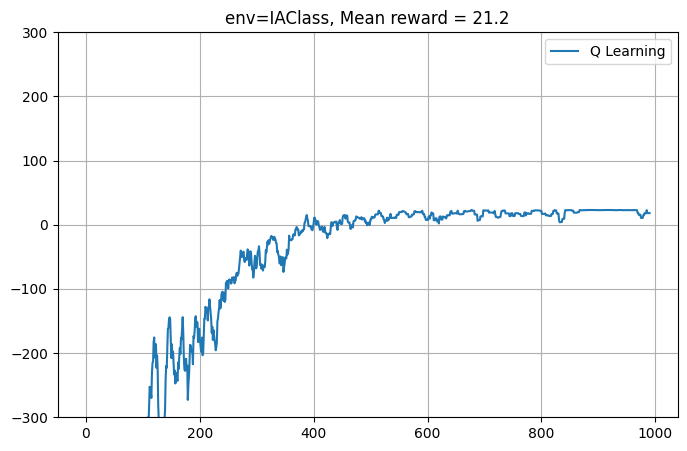


Política Otimizada:
 v  <  <  >  v  v  v  v  v  v 
 v  v  v  >  v  v  v  v  v  v 
 v  v  v  >  >  >  >  >  v  < 
 v  v  v  >  ^  ^  >  v  v  v 
 >  v  v  >  >  ^  >  v  v  v 
 >  v  v  >  >  ^  >  v  v  v 
 >  >  v  >  ^  ^  >  v  v  v 
 >  >  v  >  >  ^  >  v  v  v 
 v  >  >  >  >  ^  >  v  v  v 
 ^  <  ^  ^  ^  ^  >  >  >  G 




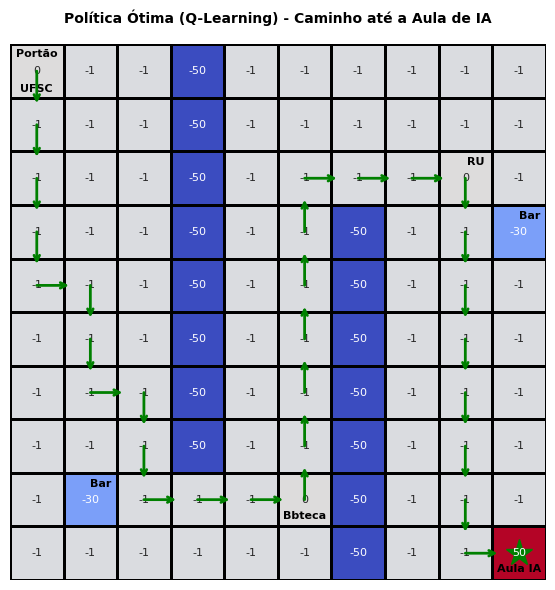

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

# Parâmetros
alpha = 0.1
gamma = 0.99
epsilon = 1.0
epsilon_decay = 0.995
epsilon_min = 0.01
episodes = 1000

# Tabela Q
q_table = np.zeros((env.observation_space.n, env.action_space.n))

# Histórico
rewards_history = []

# Treinamento Q-Learning
for episode in range(episodes):
    state = env.reset()
    done = False
    total_reward = 0

    while not done:
        if np.random.rand() < epsilon:
            action = env.action_space.sample()
        else:
            action = np.argmax(q_table[state])

        next_state, reward, done, _ = env.step(action)

        best_next_action = np.argmax(q_table[next_state])
        td_target = reward + gamma * q_table[next_state][best_next_action]
        q_table[state][action] += alpha * (td_target - q_table[state][action])

        state = next_state
        total_reward += reward

    epsilon = max(epsilon_min, epsilon * epsilon_decay)
    rewards_history.append(total_reward)

# Plot recompensas
window = 10
smoothed_rewards = np.convolve(rewards_history, np.ones(window)/window, mode='valid')
mean_reward_last_100 = np.mean(rewards_history[-100:])

plt.figure(figsize=(8, 5))
plt.plot(smoothed_rewards, label="Q Learning")
plt.title(f"env=IAClass, Mean reward = {mean_reward_last_100:.1f}")
plt.ylim(-300, 300)
plt.grid(True)
plt.legend()
plt.show()

# Politica otima aprendida
print("\nPolítica Otimizada:")

# Cima      ^
# Direita   >
# Baixo     v
# Esquerda  <

action_symbols = ['^', '>', 'v', '<']

for r in range(env.grid_size):
    row_str = ""
    for c in range(env.grid_size):
        state = r * env.grid_size + c
        if (r, c) == env.goal_pos:
            row_str += " G "
        else:
            best_a = np.argmax(q_table[state])
            row_str += f" {action_symbols[best_a]} "
    print(row_str)

# GRafico
current_state = env.start_pos
optimal_path = [current_state]
max_steps = env.max_steps
steps = 0

while current_state != env.goal_pos and steps < max_steps:
    state_idx = current_state[0] * env.grid_size + current_state[1]
    best_action = np.argmax(q_table[state_idx])

    row, col = current_state
    if best_action == 0: row -= 1      # Cima
    elif best_action == 1: col += 1    # Direita
    elif best_action == 2: row += 1    # Baixo
    elif best_action == 3: col -= 1    # Esquerda

    row = max(0, min(env.grid_size - 1, row))
    col = max(0, min(env.grid_size - 1, col))

    current_state = (row, col)
    optimal_path.append(current_state)
    steps += 1

print("\n")

# Visualizacao melhoraDA
plt.figure(figsize=(6, 6))

cmap = sns.color_palette("vlag", as_cmap=True)

ax = sns.heatmap(env.reward_map, annot=True, fmt=".0f", cmap="coolwarm", cbar=False,
                 linewidths=1, linecolor='black', square=True,
                 annot_kws={"size": 8})

# Rótulos
ax.text(0.5, 0.5, "Portão\n\n\nUFSC", ha='center', va='center', fontsize=8, fontweight='bold')
ax.text(1.7, 8.2, "Bar",              ha='center', va='center', fontsize=8, fontweight='bold')
ax.text(9.7, 3.2, "Bar",              ha='center', va='center', fontsize=8, fontweight='bold')
ax.text(8.7, 2.2, "RU",               ha='center', va='center', fontsize=8, fontweight='bold')
ax.text(5.5, 8.8, "Bbteca",           ha='center', va='center', fontsize=8, fontweight='bold')
ax.text(9.5, 9.8, "Aula IA",          ha='center', va='center', fontsize=8, fontweight='bold')

plt.title("Política Ótima (Q-Learning) - Caminho até a Aula de IA", fontsize=10, fontweight='bold', pad=15)
plt.xticks([])
plt.yticks([])

# Desenhando as setas do caminho ótimo
for i in range(len(optimal_path) - 1):
    curr_r, curr_c = optimal_path[i]
    next_r, next_c = optimal_path[i+1]

    start_y, start_x = curr_r + 0.5, curr_c + 0.5
    end_y, end_x = next_r + 0.5, next_c + 0.5

    dx = (end_x - start_x) * 0.6
    dy = (end_y - start_y) * 0.6

    ax.annotate("",
                xy=(start_x + dx, start_y + dy), xycoords='data',
                xytext=(start_x, start_y), textcoords='data',
                arrowprops=dict(arrowstyle="->", color="green", lw=2, shrinkA=0, shrinkB=0))

end_y, end_x = optimal_path[-1][0] + 0.5, optimal_path[-1][1] + 0.5
ax.plot(end_x, end_y, 'g*', markersize=20)

plt.tight_layout()
plt.show()

### Questão 3: DQN (Deep Q-Network)
Implementação de um algoritmo DQN utilizando PyTorch para rodar no ambiente customizado.

Treinando DQN... Episódio: 638/1000 | Epsilon: 0.061 | Recompensa Atual: 21.0
✅ Convergência atingida no episódio 638! Caminho encontrado.


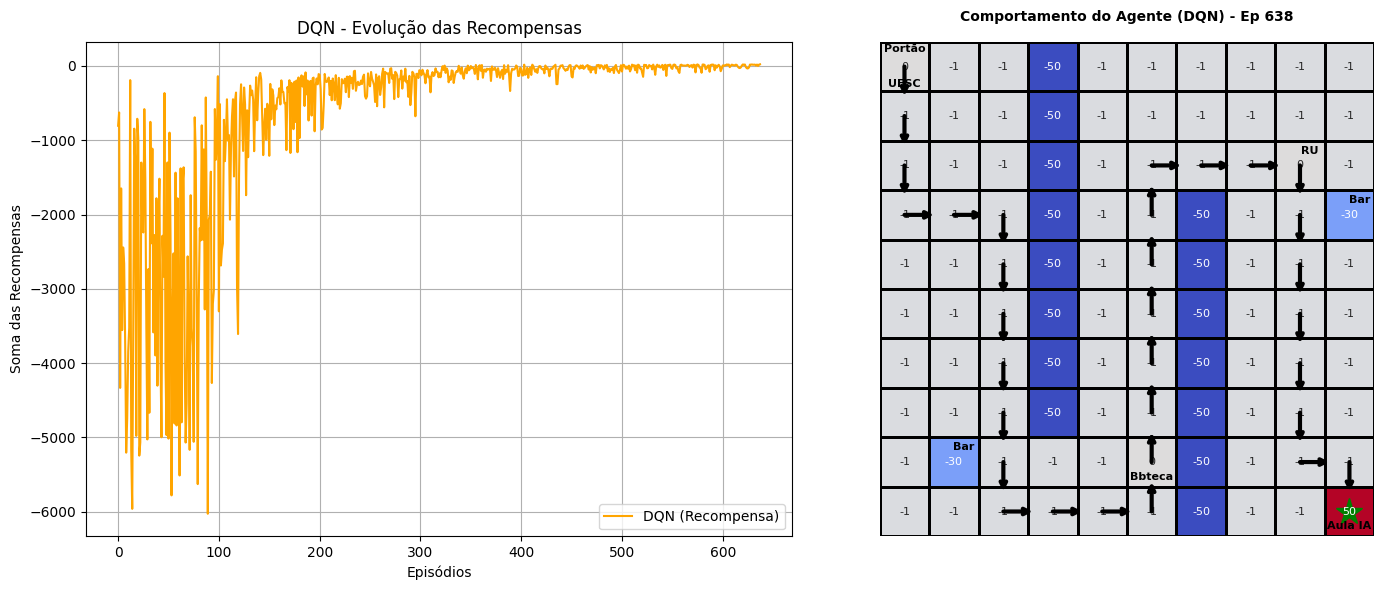

In [ ]:
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

import torch
import torch.nn as nn
import torch.optim as optim
import random
from collections import deque
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import clear_output

# Definindo a Rede Neural para o DQN
class DQN(nn.Module):
    def __init__(self, state_size, action_size):
        super(DQN, self).__init__()
        self.fc1 = nn.Linear(state_size, 64)
        self.fc2 = nn.Linear(64, 64)
        self.fc3 = nn.Linear(64, action_size)

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        return self.fc3(x)

def get_state_tensor(state_idx, grid_size=10):
    row = state_idx // grid_size
    col = state_idx % grid_size
    return torch.FloatTensor([row / (grid_size - 1), col / (grid_size - 1)])

# Hiperparâmetros do DQN
state_size = 2
action_size = 4
batch_size = 32
gamma = 0.95
epsilon = 1.5
epsilon_decay = 0.995
epsilon_min = 0.05
lr = 0.001
memory = deque(maxlen=2000)
dqn_episodes = 1000

model = DQN(state_size, action_size)
optimizer = optim.Adam(model.parameters(), lr=lr)
loss_fn = nn.MSELoss()
dqn_rewards = []

# Treinamento DQN
for episode in range(dqn_episodes):
    state_idx = env.reset()
    state = get_state_tensor(state_idx)
    total_reward = 0
    done = False

    while not done:
        # Epsilon-greedy
        if random.random() < epsilon:
            action = env.action_space.sample()
        else:
            with torch.no_grad():
                q_values = model(state)
                action = torch.argmax(q_values).item()

        next_state_idx, reward, done, _ = env.step(action)
        next_state = get_state_tensor(next_state_idx)

        # Salvar na memória de replay
        memory.append((state, action, reward, next_state, done))
        state = next_state
        total_reward += reward

        # Treinamento
        if len(memory) >= batch_size:
            batch = random.sample(memory, batch_size)
            states = torch.stack([x[0] for x in batch])
            actions = torch.LongTensor([x[1] for x in batch]).unsqueeze(1)
            rewards = torch.FloatTensor([x[2] for x in batch])
            next_states = torch.stack([x[3] for x in batch])
            dones = torch.FloatTensor([x[4] for x in batch])

            curr_q = model(states).gather(1, actions).squeeze(1)
            with torch.no_grad():
                next_q = model(next_states).max(1)[0]
                target_q = rewards + gamma * next_q * (1 - dones)

            loss = loss_fn(curr_q, target_q)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

    epsilon = max(epsilon_min, epsilon * epsilon_decay)
    dqn_rewards.append(total_reward)

    # Verifica o caminho atual para ver se chegou ao objetivo e se é ótimo
    current_state = env.start_pos
    dqn_path = [current_state]
    max_steps = 100
    steps = 0
    reached_goal = False

    while current_state != env.goal_pos and steps < max_steps:
        state_idx = current_state[0] * env.grid_size + current_state[1]
        state_tensor = get_state_tensor(state_idx)

        with torch.no_grad():
            q_values = model(state_tensor)
            best_action = torch.argmax(q_values).item()

        row, col = current_state
        if best_action == 0: row -= 1
        elif best_action == 1: col += 1
        elif best_action == 2: row += 1
        elif best_action == 3: col -= 1

        row = max(0, min(env.grid_size - 1, row))
        col = max(0, min(env.grid_size - 1, col))

        current_state = (row, col)
        dqn_path.append(current_state)

        if current_state == env.goal_pos:
            reached_goal = True
            break

        # Se o agente ficar preso repetindo ações, encerra a rota
        if len(dqn_path) > 2 and dqn_path[-1] == dqn_path[-3]:
            break

        steps += 1

    # Condição de parada: chegou ao objetivo com recompensas estáveis
    is_optimal = reached_goal and total_reward>=20


    if (episode + 1) % 25 == 0 or (episode + 1) == dqn_episodes or is_optimal:
        clear_output(wait=True)
        print(f"Treinando DQN... Episódio: {episode + 1}/{dqn_episodes} | Epsilon: {epsilon:.3f} | Recompensa Atual: {total_reward}")
        if is_optimal:
            print(f"✅ Convergência atingida no episódio {episode + 1}! Caminho encontrado.")

        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

        # grafico de recompensas
        ax1.plot(dqn_rewards, label="DQN (Recompensa)", color='orange')
        ax1.set_title("DQN - Evolução das Recompensas")
        ax1.set_xlabel("Episódios")
        ax1.set_ylabel("Soma das Recompensas")
        ax1.grid(True)
        ax1.legend()

        # grafico de comportamento
        cmap = sns.color_palette("vlag", as_cmap=True)

        sns.heatmap(env.reward_map, annot=True, fmt=".0f", cmap="coolwarm", cbar=False,
                         linewidths=1, linecolor='black', square=True,
                         annot_kws={"size": 8}, ax=ax2)

        # Rótulos
        ax2.text(0.5, 0.5, "Portão\n\n\nUFSC", ha='center', va='center', fontsize=8, fontweight='bold')
        ax2.text(1.7, 8.2, "Bar",             ha='center', va='center', fontsize=8, fontweight='bold')
        ax2.text(9.7, 3.2, "Bar",             ha='center', va='center', fontsize=8, fontweight='bold')
        ax2.text(8.7, 2.2, "RU",              ha='center', va='center', fontsize=8, fontweight='bold')
        ax2.text(5.5, 8.8, "Bbteca",          ha='center', va='center', fontsize=8, fontweight='bold')
        ax2.text(9.5, 9.8, "Aula IA",         ha='center', va='center', fontsize=8, fontweight='bold')

        ax2.set_title(f"Comportamento do Agente (DQN) - Ep {episode + 1}", fontsize=10, fontweight='bold', pad=15)
        ax2.set_xticks([])
        ax2.set_yticks([])

        for i in range(len(dqn_path) - 1):
            curr_r, curr_c = dqn_path[i]
            next_r, next_c = dqn_path[i+1]

            start_y, start_x = curr_r + 0.5, curr_c + 0.5
            end_y, end_x = next_r + 0.5, next_c + 0.5

            dx = (end_x - start_x) * 0.6
            dy = (end_y - start_y) * 0.6

            ax2.annotate("",
                        xy=(start_x + dx, start_y + dy), xycoords='data',
                        xytext=(start_x, start_y), textcoords='data',
                        arrowprops=dict(arrowstyle="->", color="green", lw=2, shrinkA=0, shrinkB=0))

        end_y, end_x = dqn_path[-1][0] + 0.5, dqn_path[-1][1] + 0.5
        ax2.plot(end_x, end_y, 'g*', markersize=20)

        plt.tight_layout()
        plt.show()

        if is_optimal:
            break